# <span style="color:green"> Numerical Simulation Laboratory (NSL) </span>
## <span style="color:blue">  Numerical exercises 8</span>

In [2]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import math

# Exercise 08.1

## Results

The goal of this exercise is to variationally estimate the ground-state energy of a single quantum particle in a one-dimensional space confined by a symmetric double-well potential:
$$V(x) = x^4 - \frac{5}{2}x^2$$

Since this model is not analytically solvable, we use the Variational Monte Carlo (VMC) method. According to the variational principle, the expectation value of the Hamiltonian over a trial wavefunction $\Psi_T(x)$ provides an upper bound to the true ground-state energy $E_0$:
$$
\langle \hat{H} \rangle_T = \frac{\int dx \Psi^*_T(x) \hat{H} \Psi_T(x)}{\int dx |\Psi_T(x)|^2} \ge E_0
$$

#### 1. Trial Wavefunction
Because the potential has two symmetric minima, a suitable trial wavefunction can be modeled as the sum of two Gaussian functions centered at $-\mu$ and $\mu$:
$$
\Psi_T^{\sigma,\mu}(x) \propto e^{-\frac{(x-\mu)^2}{2\sigma^2}} + e^{-\frac{(x+\mu)^2}{2\sigma^2}}
$$
where $\sigma$ and $\mu$ are variational parameters.

#### 2. Metropolis Sampling and Local Energy
To evaluate $\langle \hat{H} \rangle_T$ numerically, we rewrite the expectation value as an integral over the probability density $P(x)$:
$$
\langle \hat{H} \rangle_T = \int dx \left( \frac{|\Psi_T(x)|^2}{\int dy |\Psi_T(y)|^2} \right) \left( \frac{\hat{H} \Psi_T(x)}{\Psi_T(x)} \right) = \int dx \, P(x) \, E_{\text{loc}}(x)
$$
where:
* **Probability Distribution:** $P(x) = \frac{|\Psi_T(x)|^2}{\int dx |\Psi_T(x)|^2}$
* **Local Energy:** $E_{\text{loc}}(x) = \frac{\hat{H} \Psi_T(x)}{\Psi_T(x)} = -\frac{1}{2}\frac{\Psi''_T(x)}{\Psi_T(x)} + V(x)$ (assuming $\hbar = 1$ and $m = 1$).

#### 3. Markov Chain & Metropolis Algorithm
The positions $x$ distributed according to $P(x)$ are sampled via a Markov chain using the Metropolis algorithm:
* **Proposal:** A new trial position is proposed via a uniform distribution: $x_{\text{new}} = x_{\text{old}} + \mathcal{U}(-\text{step}, \text{step})$.
* **Acceptance Probability:** The move is accepted with probability:
  $$P_{\text{acc}} = \min\left(1, \frac{|\Psi_T(x_{\text{new}})|^2}{|\Psi_T(x_{\text{old}})|^2}\right)$$
* **Tuning:** The parameter `step` (amplitude $\delta x$) is tuned to maintain an acceptance rate around $50\%$. In our implementation, we use `step = 2.5` starting from initial variational parameters $\sigma = 0.8$ and $\mu = 0.8$.

#### 4. Data Blocking
At each step of the Markov chain, the local energy $E_{\text{loc}}(x)$ is computed. To properly estimate statistical uncertainties and account for autocorrelations in the Markov chain, the measurements are analyzed using the **data blocking method** (dividing the total steps into blocks, computing block averages, and tracking progressive means and errors).
    
---

**Exercise**

Write a Variational Monte Carlo code for a single quantum particle in 1D which exploits the Metropolis algorithm to sample the square modulus of our trial wave function $|\Psi_T^{\sigma,\mu}(x)|^2$ using an uniform transition probability $T(x_{new}|x_{old})$. By using data blocking, the code should be able to compute the expectation value for the Hamiltonian

$$
\langle {\hat H} \rangle_T = 
\frac{\int dx \Psi^*_T(x) {\hat H} \Psi_T(x)}
{\int dx |\Psi_T(x)|^2} = 
\int dx \frac{|\Psi_T(x)|^2}{\int dx |\Psi_T(x)|^2} \frac{{\hat H} \Psi_T(x)}{\Psi_T(x)}
$$

which can be used to find the parameters that minimize this quantity. Use $\hbar = 1$ and $m=1$.
<span style="color:red">Note that to measure $\langle {\hat H} \rangle_T$ you need the analytical calculation of:</span>
    
$$
\frac{{-\frac{\hbar^2}{2m}\frac{\partial^2}{\partial x^2}} \Psi_T^{\sigma,\mu}(x)}{\Psi_T^{\sigma,\mu}(x)}
$$

# Exercise 08.2

## Resolution

To find the optimal variational parameters $(\mu, \sigma)$ that minimize the energy expectation value $\langle \hat{H} \rangle_T$, we implemented a Simulated Annealing (SA) optimization scheme. By treating the variational expectation value $\langle \hat{H} \rangle_T$ as a cost function, the SA algorithm explores the parameter space.

#### 1. Optimization Scheme & Cooling Law
The optimization starts at an initial fictitious temperature $T_0 = 1.0$ and cools down to a final temperature $T_f = 10^{-2}$ over a total of $N_{\text{temp}} = 400$ temperature steps. At each temperature, $20$ trial moves of the variational parameters $(\mu,\sigma)$ are attempted ($8000$ moves in total). The cooling follows a geometric decay law:
$$T_{k+1} = \alpha \, T_{k}, \qquad \alpha = \left(\frac{T_f}{T_0}\right)^{\frac{1}{N_{\text{temp}} - 1}} \approx 0.9885$$
so that the last temperature step is exactly $T_f$.

When $|\Delta E|$ becomes comparable to this noise, which happens at low $T$ because the energy is very flat near the minimum, the accept/reject decision is partly driven by statistical fluctuations. The parameters therefore keep fluctuating inside the flat region around the minimum instead of converging to a single point. A slow geometric cooling favours a thorough exploration at high $T$ and a refinement at low $T$, but it does not guarantee convergence to the global minimum.

#### 2. Simulated Annealing Step
At each SA step:
1. **Trial Parameter Move:** New variational parameters are proposed via a uniform random displacement:
   $$\mu_{\text{new}} = \mu_{\text{old}} + \delta\mu, \quad \sigma_{\text{new}} = \sigma_{\text{old}} + \delta\sigma$$
   where $\delta\mu \sim \mathcal{U}[-\delta, \delta]$ and $\delta\sigma \sim \mathcal{U}[-\delta, \delta]$. A physical bound ($\sigma > 0$) is enforced.
2. **Energy Evaluation:** The expectation value $\langle \hat{H} \rangle_{\text{new}}$ corresponding to the trial wavefunction $\Psi_T^{\sigma_{\text{new}}, \mu_{\text{new}}}(x)$ is computed using the VMC Metropolis sampling routine developed in Exercise 08.1.
3. **Metropolis Acceptance:** The proposed parameters are accepted with probability:
   $$P_{\text{acc}} = \min \left( 1, \exp\left( -\frac{\langle \hat{H} \rangle_{\text{new}} - \langle \hat{H} \rangle_{\text{old}}}{T} \right) \right)$$
   If accepted, the state updates to $(\mu_{\text{new}}, \sigma_{\text{new}})$; otherwise, the previous parameters are retained.

#### 3. Final High-Statistics Run
Once the SA procedure terminates and the optimal parameters $(\mu^*, \sigma^*)$ are obtained, a final, long VMC simulation is executed with significantly higher statistics (increased number of blocks and steps per block). This generates the final, converged estimate of the ground-state energy $\langle \hat{H} \rangle_{\text{min}}$ with its statistical uncertainties, as well as the sampled positions $x \sim |\Psi_T^{\mu^*, \sigma^*}(x)|^2$ needed to build the ground-state probability density histogram.


#### Summary of Simulation Parameters
* **Cooling Schedule:** $N_T = 400$ temperature steps
* **SA Energy Estimation:** $N_{\text{samples}} = 80\,000$ MC steps per evaluation, with $N_{\text{eq}} = 5\,000$ internal equilibration steps
* **Final VMC Production Run:** $N_{\text{blocks}} = 800$ blocks for data blocking analysis


## Results
* **Optimal Parameters:** $\mu = 0.814139, \quad \sigma = 0.608202$
* **Minimum Variational Energy:** $\langle \hat{H} \rangle_{\text{min}} = -0.453575$
* **Exact Ground-State Reference:** $E_0 \approx -0.460466$


The obtained minimum energy strictly satisfies the Rayleigh–Ritz variational principle ($\langle \hat{H} \rangle \ge E_0$), remaining well above the exact ground-state energy ($-0.453575 \ge -0.460466$). Increasing the number of Monte Carlo samples and equilibration steps per SA evaluation successfully suppressed statistical fluctuations, preventing artificial downward energy bias and confirming that the symmetric double-Gaussian trial wavefunction provides an accurate representation of the double-well ground state.

---

**Exercise** 

To find the parameters $\sigma$ and $\mu$ which minimize $\langle {\hat H} \rangle_T$, extend your Variational Monte Carlo code to face the variational optimization problem via a <span style="color:red">Simulated Annealing (SA) algorithm</span>.

Choose an appropriate starting temperature for your SA algorithm and an appropriate temperature-update-law to make the optimization work.

Compute $\langle {\hat H} \rangle_T$ with enough statistics in order to be able to measure the lowering of $\langle {\hat H} \rangle_T$ once the variational parameters are moved.- <span style="color:red">Show a picture of $\langle {\hat H} \rangle_T$ (with statistical uncertainties) as a function of the SA steps of the algorithm</span>
- you could also show a picture of the trajectory of the SA algorithm in the variational parameter space as a function of the SA steps
- <span style="color:red">show a picture of the estimation of $\langle {\hat H} \rangle_T$ </span> and its statistical uncertainty as a function of the number of blocks/MC steps <span style="color:red">for the set of parameters which minimize $\langle {\hat H} \rangle_T$</span>
- <span style="color:red">show also a picture **of the sampled** $|\Psi_T(x)|^2$</span> by filling a histogram with the sampled configurations, moreover compare it with the analytic curve of $|\Psi_T(x)|^2$ and with the numerical solution obtained by transforming the Schrodinger equation into a matrix equation (see below the supplementary material).

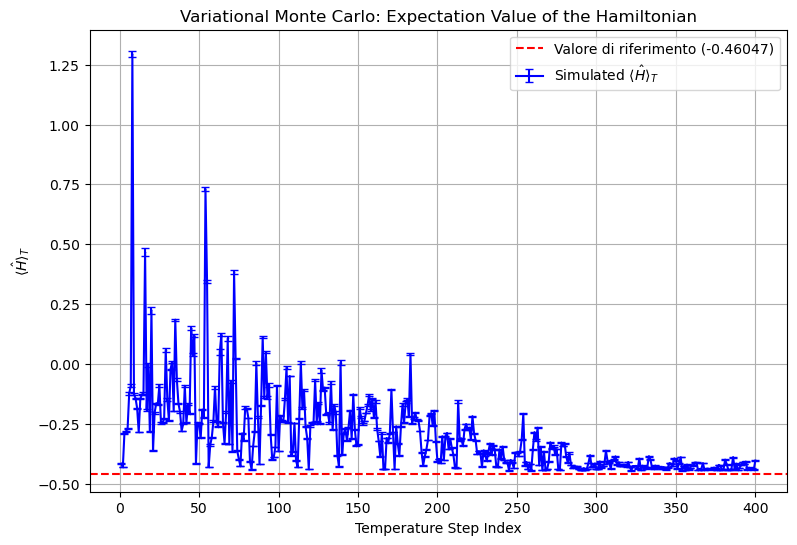

In [46]:
data1 = np.loadtxt("energy_vs_T.txt")

x1 = data1[:, 0]     
mean1 = data1[:, 4]  
err1 = data1[:, 5]   

plt.figure(figsize=(9, 6))
plt.title("Variational Monte Carlo: Expectation Value of the Hamiltonian")

# Plot con barre d'errore
plt.errorbar(x1, mean1, yerr=err1, label="Simulated $\\langle \\hat{H} \\rangle_T$", capsize=3, color='blue', marker='.',markersize=0.3)

# Linea orizzontale di riferimento
target_val = -0.46046587969271513
plt.axhline(y=target_val, color='red', linestyle='--', linewidth=1.5, 
            label=f"Valore di riferimento ({target_val:.5f})")

plt.xlabel("Temperature Step Index")
plt.ylabel("$\\langle \\hat{H} \\rangle_T$")
plt.legend()
plt.grid(True)

plt.show()

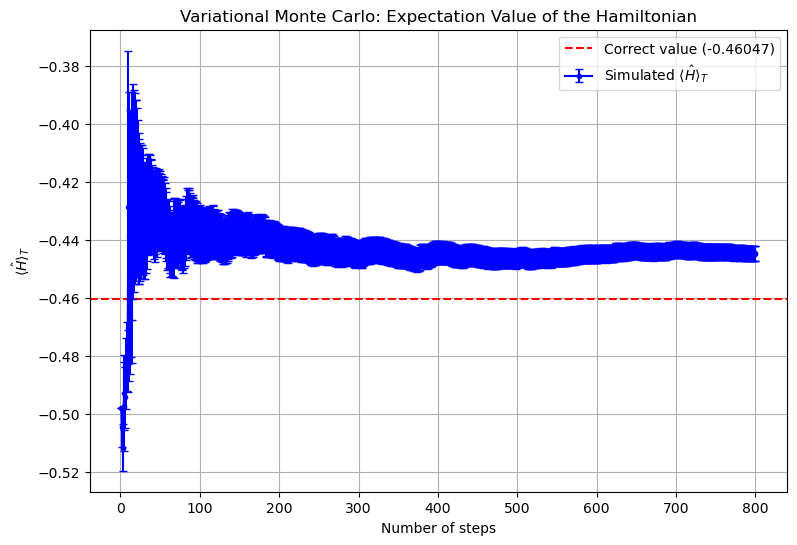

In [48]:
data1 = np.loadtxt("data_optimal.txt")

x1 = data1[:, 0]
mean1 = data1[:, 1]
err1 = data1[:, 2]

plt.figure(figsize=(9, 6))
plt.title("Variational Monte Carlo: Expectation Value of the Hamiltonian")
# Linea orizzontale di riferimento
target_val = -0.46046587969271513
plt.axhline(y=target_val, color='red', linestyle='--', linewidth=1.5, 
            label=f"Correct value ({target_val:.5f})")
# Plot con barre d'errore
plt.errorbar(x1, mean1, yerr=err1, label="Simulated $\\langle \\hat{H} \\rangle_T$", capsize=3, color='blue', marker='.')

plt.xlabel("Number of steps")
plt.ylabel("$\\langle \\hat{H} \\rangle_T$")
plt.legend()
plt.grid(True)

plt.show()

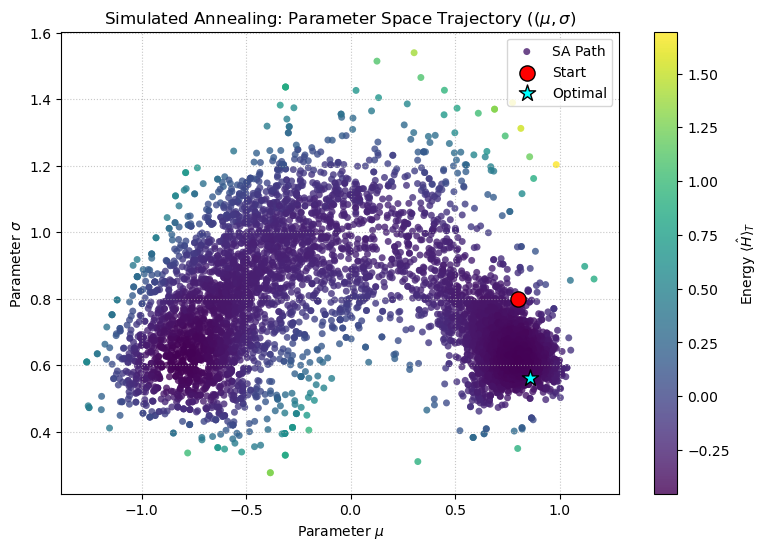

In [50]:
opt_data = np.loadtxt("optimization.txt")

sa_steps = opt_data[:, 0]
temperature = opt_data[:, 1]
sigma = opt_data[:, 2]
mu = opt_data[:, 3]
energy = opt_data[:, 4]

plt.figure(figsize=(9, 6))
plt.title("Simulated Annealing: Parameter Space Trajectory ($(\\mu, \\sigma$)")

# Scatter plot con i punti colorati in base all'energia stimata
sc = plt.scatter(mu, sigma, c=energy, cmap='viridis', s=25, edgecolor='none', alpha=0.8, label="SA Path")
cbar = plt.colorbar(sc)
cbar.set_label(r"Energy $\langle \hat{H} \rangle_T$")


plt.scatter(mu[0], sigma[0], color='red', s=120, marker='o', edgecolors='black', label='Start', zorder=5)
plt.scatter(mu[-1], sigma[-1], color='cyan', s=150, marker='*', edgecolors='black', label='Optimal', zorder=5)

plt.xlabel(r"Parameter $\mu$")
plt.ylabel(r"Parameter $\sigma$")
plt.legend(loc="upper right")
plt.grid(True, linestyle=":", alpha=0.7)

plt.show()

Best parameters found at step 7324:
mu = 0.81414, sigma = 0.60820


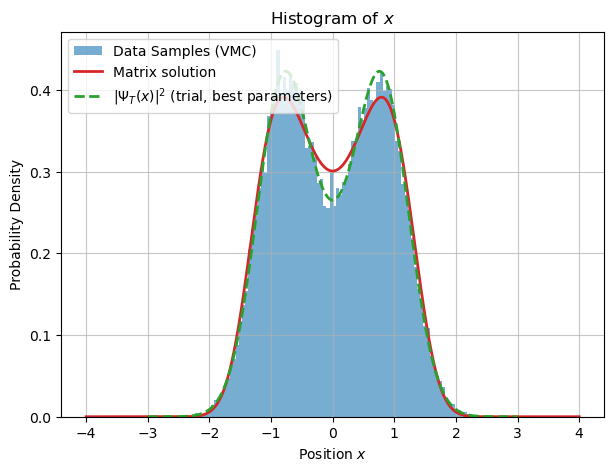

In [52]:
opt_data = np.loadtxt("optimization.txt")
min_energy_idx = np.argmin(opt_data[:, 4])  #cerco nella colonna 4 il miglior valore
# all'indice appena trovato estraggo la corrispondente  coppia di valori
sigma_best = opt_data[min_energy_idx, 2]   
mu_best = opt_data[min_energy_idx, 3]

print(f"Best parameters found at step {opt_data[min_energy_idx, 0]:.0f}:")
print(f"mu = {mu_best:.5f}, sigma = {sigma_best:.5f}")

x = np.linspace(-3.0, 3.0, 500)

def expected_H(x, mu, sigma):
    return (
        np.exp(-((x - mu) ** 2) / (2 * sigma**2))
        + np.exp(-((x + mu) ** 2) / (2 * sigma**2))
    ) / (2 * np.pi**0.5 * sigma * (1 + np.exp(-(mu**2) / sigma**2))) ** 0.5

psi_best = expected_H(x, mu_best, sigma_best)

positions = np.loadtxt("histogram_positions.txt")

fig = plt.figure(figsize=(7, 5))

plt.hist(positions, bins=100, density=True, alpha=0.6, color="C0", label="Data Samples (VMC)")

N = 1000
xg = np.linspace(-4, 4, N)
dx = xg[1] - xg[0]
V = xg**4 - 2.5 * xg**2
Hm = (np.diag(1 / dx**2 + V)
      + np.diag(-0.5 / dx**2 * np.ones(N - 1), 1)
      + np.diag(-0.5 / dx**2 * np.ones(N - 1), -1))
E, phi = np.linalg.eigh(Hm)
plt.plot(xg, phi[:, 0]**2 / dx, label="Matrix solution", c="C3", lw=2)

plt.plot(
    x, psi_best**2, label=r"$|\Psi_T(x)|^2$ (trial, best parameters)", linestyle="--", c="C2", lw=2
)

plt.title(r"Histogram of $x$")
plt.xlabel("Position $x$")
plt.ylabel("Probability Density")

plt.legend(loc="upper left")
plt.grid(True, which="major", alpha=0.7)
plt.grid(True, which="minor", linestyle=":", alpha=0.5)

plt.show()
